# 01. 주제 경계 후보 탐지를 위한 청킹

#### 활용 데이터 : TS3003b.txt
- 상단 3줄(회의 대주제·참여자·일시)은 청킹하지 않고 메타데이터로만 보관
- 임베딩 모델 : `BAAI/bge-m3` 토크나이저
- Chunking 방식: **발화 단위 묶기**. 발화 중간에서 자르지 않고, 발화를 순서대로 쌓다가 `CHUNK_SIZE` 토큰을 넘기 직전에 청크 닫기
- Overlap : 이전 청크 끝에서 `CHUNK_OVERLAP` 토큰 이내의 발화를 다음 청크 앞에 다시 포함
- 청크별 메타데이터: `chunk_index`(청킹 순서), `token_count`, 그리고 3단계에서 `[발화번호]` 문맥을 만들 때 쓸 `utterance_start`/`utterance_end`

#### chunk_size / chunk_overlap 선정 근거 (TS3003b 실측)

| 항목 | 값 |
|---|---|
| 발화 수 | 714개 (그중 3토큰 이하 `네.`/`음.` 등 244개) |
| 전체 토큰 (BGE-M3) | 6,148 토큰 / 약 37분 → **분당 약 166 토큰** |
| 발화당 토큰 | 평균 8.6 / 중앙값 7 / 최대 44 |


| chunk_size / overlap | 청크 수 | 청크당 발화 수 | 판단 |
|---|---|---|---|
| 128 / 32 | 64 | 14.7 | 짧은 응답 비중이 커서 임베딩이 불안정 |
| **200 / 40** | **38** | **23.1** | **약 1분 분량. 짧은 안건(공지 사항 등)도 1~2청크로 잡힘** |
| 256 / 64 | 32 | 29.9 | 사용 가능하나 짧은 안건이 앞뒤 안건과 섞이기 시작 |
| 512 / 128 | 16 | 59.1 | 한 청크에 여러 안건이 섞여 경계 위치가 흐려짐 |

→ **기본값 : `CHUNK_SIZE = 200`, `CHUNK_OVERLAP = 40`(20%)**
- 임베딩 유사도로 경계를 찾으려면 한 안건이 최소 2~3개 청크에 걸쳐야 인접 청크 간 유사도 하락이 드러남. 200토큰이면 3~5분 길이의 일반 안건이 3~5청크가 됨
- 참고 : BGE-M3 입력 한도는 8,192토큰
- 오버랩 20%는 경계 직전·직후 발화가 양쪽 청크에 함께 보이도록 하는 최소 수준. 너무 크면 인접 청크끼리 유사도가 높아져 경계 신호가 약해짐

In [1]:
# --------------------------------------------------------------------------------------------------
# 1-0. 설정 
# 경로/파라미터는 해당 셀에서만 수정
# transformers, sentence-transformers 신규 설치
# --------------------------------------------------------------------------------------------------
from pathlib import Path

# ── 경로 ──────────────────────────────────────────────
BASE_DIR = Path.cwd().parent                       # playground/chaewon
INPUT_PATH = BASE_DIR / "dataset" / "TS3003b.txt"  # 청킹할 전사문
OUTPUT_DIR = BASE_DIR / "outputs" / "chunks"       # 결과 저장 폴더 (outputs/는 .gitignore 대상)

# ── 전사문 형식 ───────────────────────────────────────
HEADER_LINES = 3            # 상단 메타데이터 줄 수 (회의 대주제 / 참여자 / 일시) → 청킹 제외
UTTERANCE_SEPARATOR = "\n"  # 청크 안에서 발화를 이어 붙일 구분자

# ── 토크나이저 / 청킹 파라미터 ─────────────────────────
TOKENIZER_NAME = "BAAI/bge-m3"  # 임베딩 모델과 같은 토크나이저로 토큰 수 계산
CHUNK_SIZE = 200                # 청크당 최대 토큰 수
CHUNK_OVERLAP = 40              # 인접 청크가 공유할 최대 토큰 수 (발화 단위로 맞춤)

# 파라미터 비교용 후보 (마지막 셀)
COMPARE_CONFIGS = [(128, 32), (160, 32), (200, 40), (256, 64), (320, 64), (512, 128)]

In [2]:
# --------------------------------------------------------------------------------------------------
# 1-1. 전사문 읽기 - 머리말, 발화 분리
# transformer 때문에 실행 조금 걸릴 수 있음 - 실행 시 조금 기다려주기!
# --------------------------------------------------------------------------------------------------
import json
from transformers import AutoTokenizer

assert 0 <= CHUNK_OVERLAP < CHUNK_SIZE, "CHUNK_OVERLAP은 0 이상, CHUNK_SIZE 미만이어야 합니다."


def load_transcript(path, header_lines):
    lines = path.read_text(encoding="utf-8-sig").splitlines()
    header = {}
    for line in lines[:header_lines]:
        key, _, value = line.partition(":")
        header[key.strip()] = value.strip()
    utterances = [line.strip() for line in lines[header_lines:] if line.strip()]
    return header, utterances


header, utterances = load_transcript(INPUT_PATH, HEADER_LINES)
meeting_id = INPUT_PATH.stem

print("머리말 (청킹 제외):", json.dumps(header, ensure_ascii=False, indent=2))
print(f"발화 수: {len(utterances)}")
print("첫 발화 5개:", utterances[:5])

c:\Users\user\Desktop\한화내일아카데미\remeet\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


머리말 (청킹 제외): {
  "회의 대주제": "Real Reaction 신제품 TV 리모컨 개발 프로젝트 2차 회의 - 기능 설계",
  "참여자": "프로젝트 매니저, 산업 디자이너, UI 디자이너, 마케팅 담당자 (4명)",
  "일시": "2004-10-11 (회의 길이 약 37분)"
}
발화 수: 714
첫 발화 5개: ['좋아요.', '다들 다시 자리 찾으셨죠? 네?', '네.', '좋네요.', '좋아요, 그럼']


In [3]:
# --------------------------------------------------------------------------------------------------
# 1-2. 토큰 기준 발화 단위 청킹
# --------------------------------------------------------------------------------------------------
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)


def count_tokens(text):
    # 특수 토큰(<s>, </s>)을 뺀 본문 토큰 수
    return len(tokenizer.encode(text, add_special_tokens=False))


def chunk_utterances(utterances, chunk_size, chunk_overlap, sep=UTTERANCE_SEPARATOR):
    chunks = []
    start = 0
    while start < len(utterances):
        # 1) chunk_size를 넘기 직전까지 발화를 쌓는다 (발화 1개가 chunk_size보다 길면 그 발화 하나로 청크 구성)
        end = start + 1
        while end < len(utterances) and count_tokens(sep.join(utterances[start:end + 1])) <= chunk_size:
            end += 1
        text = sep.join(utterances[start:end])
        chunks.append({
            "text": text,
            "metadata": {
                "chunk_index": len(chunks),
                "token_count": count_tokens(text),
                "utterance_start": start,    # 포함
                "utterance_end": end - 1,    # 포함
            },
        })
        if end == len(utterances):
            break
        # 2) 청크 끝에서 chunk_overlap 이내의 발화를 다음 청크 시작으로 (항상 앞으로 진행)
        next_start = end
        while next_start - 1 > start and count_tokens(sep.join(utterances[next_start - 1:end])) <= chunk_overlap:
            next_start -= 1
        start = next_start
    return chunks


chunks = chunk_utterances(utterances, CHUNK_SIZE, CHUNK_OVERLAP)
print(f"청크 수: {len(chunks)}  (chunk_size={CHUNK_SIZE}, chunk_overlap={CHUNK_OVERLAP})")

청크 수: 38  (chunk_size=200, chunk_overlap=40)


In [4]:
# --------------------------------------------------------------------------------------------------
# 1-3. 결과 확인
# --------------------------------------------------------------------------------------------------
import pandas as pd
from IPython.display import display

chunks_df = pd.DataFrame([{**c["metadata"], "preview": c["text"][:60].replace("\n", " / ")} for c in chunks])
display(chunks_df)
display(chunks_df["token_count"].describe())

# 정합성 검사: 순서, 토큰 한도(긴 단일 발화 예외), 모든 발화 포함 여부
assert chunks_df["chunk_index"].tolist() == list(range(len(chunks)))
single = chunks_df["utterance_start"] == chunks_df["utterance_end"]
assert ((chunks_df["token_count"] <= CHUNK_SIZE) | single).all()
covered = set()
for c in chunks:
    covered.update(range(c["metadata"]["utterance_start"], c["metadata"]["utterance_end"] + 1))
assert covered == set(range(len(utterances))), "누락된 발화가 있습니다."

print("\n[chunk 0]\n" + chunks[0]["text"])
print("\n[chunk 1] (앞부분이 chunk 0 끝과 겹침)\n" + chunks[1]["text"])

,chunk_index,token_count,utterance_start,utterance_end,preview
0,0,200,0,24,"좋아요. / 다들 다시 자리 찾으셨죠? 네? / 네. / 좋네요. / 좋아요, 그럼..."
1,1,200,19,45,"네. / C동이랑 E동이에요. / 그래서 / 좀 지나면, 며칠이면 끝날 거예요. /..."
2,2,193,39,62,"음, 첫 발표부터 시작하죠. / 네. / 음, 누가 먼저 할래요? / 제가 먼저 할..."
3,3,197,59,74,"음 / 이게 제가 보기에 꽤 놀라운 결과 세 가지예요. / 음, 리모컨은 못생겼다고..."
4,4,196,73,88,"채널 선택과 볼륨 선택은 음, 1부터 10까지 중요도에서 둘 다 10점을 받았어요...."
5,5,183,87,100,"음, 새로운 기능을 쓰는 걸 좋아하지만, / 아주 까다롭기도 해요. / 돈을 쉽게 ..."
6,6,189,99,110,"음, 그리고 응답자의 약 4분의 1이 리모컨 때문에 RSI가 생긴다고 생각했어요. ..."
7,7,194,108,123,"가장 많이 쓰이니까 / 튼튼해야 해요. / 쉽게 고장 나면 안 돼요. / 음, 그리..."
8,8,189,122,155,"이건 음, 주로 16세에서 25세 사람들이었어요. / 그래도 45세까지는 여전히 가..."
9,9,199,148,169,"위쪽에 있는 거로 가세요. 슬라이드 쇼요. / 그러니까 / 아. / 어. / 아, ..."


count     38.000000
mean     193.815789
std        6.176920
min      176.000000
25%      189.250000
50%      196.000000
75%      199.000000
max      200.000000
Name: token_count, dtype: float64


[chunk 0]
좋아요.
다들 다시 자리 찾으셨죠? 네?
네.
좋네요.
좋아요, 그럼
이번이 두 번째 회의예요.
그리고 어
아직도 안 돼요?
네.
어, 이제 음, 기능 설계로 들어가요.
음, 이 단계에서 중요한 건 사용자 요구 사항, 기술적 기능 설계, 작동 설계에 대해 어, 합의를 보는 거예요. 그래야 두 번째 어, 단계로 넘어갈 수 있으니까요.
하지만 먼저 이 단계부터요.
음, 먼저 공지 사항이 있어요.
냉난방 시스템에 약간의 조정이 있어요.
그래서
또 유령 마우스가 나타났네요.
그러니까 냉난방에 약간, 약간 문제가 있을 수 있다는 거고,
그건 이 어
네.
네.
C동이랑 E동이에요.
그래서
좀 지나면, 며칠이면 끝날 거예요.
어차피 추울 거라서
필요하진 않을 것 같아요.

[chunk 1] (앞부분이 chunk 0 끝과 겹침)
네.
C동이랑 E동이에요.
그래서
좀 지나면, 며칠이면 끝날 거예요.
어차피 추울 거라서
필요하진 않을 것 같아요.
그렇죠.
그다음은 안건이에요.
자
먼저 시작.
어, 이번엔 제가 회의록을 적을게요.
어, 다들 발표를 하실 거예요. 모두요.
음, 전체 어, 발표에 40분이 있어요.
그래서 어, 발표당 7분 정도로 하는 걸 제안해요,
그다음에 새 프로젝트 요구 사항에 대해 잠깐 논의하고
어, 저한테 온 거요.
그리고 어, 넣을 조작 기능과 넣지 않을 기능을 결정하는 거예요.
그래서
전부 해서 40분이 있어요.
그러니까
음, 첫 발표부터 시작하죠.
네.
음, 누가 먼저 할래요?
제가 먼저 할게요.
좋아요.
그럼
아마 이렇게 하면 더 쉬울 것 같은데 음


In [5]:
# --------------------------------------------------------------------------------------------------
# 1-4. 저장
# 현재는 각 단계별로 저장하지 않도록 함
# 만약, 단계별로 저장하고 싶다면 주석 풀고 실행하면 "outputs/chunks" 디렉토리 내 <회의ID>_chunks.json 파일로 저장됨
# utterances도 함께 저장하여 utteraces_start~utterance_end로 [발화번호] 텍스트 형태의 경계 앞뒤 문맥을 다시 만들 수 있음
# output에는 크게 아래와 같은 정보를 포함함
# > 회의ID / metadata(회의주제, 참여자, 일시) / chunking 정보 / utterances 정보(발화별 순서 인덱스) / chunks(각 청킹값)

# chunks 예)
# {'text': '좋아요.\n다들 다시 자리 찾으셨죠? 네?\n네.\n좋네요.\n좋아요, 그럼\n이번이 두 번째 회의예요.\n그리고 어\n아직도 안 돼요?\n네.\n어, 이제 음, 기능 설계로 들어가요.\n음, 이 단계에서 중요한 건 사용자 요구 사항, 기술적 기능 설계, 작동 설계에 대해 어, 합의를 보는 거예요. 그래야 두 번째 어, 단계로 넘어갈 수 있으니까요.\n하지만 먼저 이 단계부터요.\n음, 먼저 공지 사항이 있어요.\n냉난방 시스템에 약간의 조정이 있어요.\n그래서\n또 유령 마우스가 나타났네요.\n그러니까 냉난방에 약간, 약간 문제가 있을 수 있다는 거고,\n그건 이 어\n네.\n네.\nC동이랑 E동이에요.\n그래서\n좀 지나면, 며칠이면 끝날 거예요.\n어차피 추울 거라서\n필요하진 않을 것 같아요.',
#    'metadata': {'chunk_index': 0,
#     'token_count': 200,
#     'utterance_start': 0,
#     'utterance_end': 24}}
# --------------------------------------------------------------------------------------------------
chunk_result = {
    "meeting_id": meeting_id,
    "metadata": header,
    "chunking": {
        "tokenizer": TOKENIZER_NAME,
        "unit": "token (special tokens excluded)",
        "strategy": "utterance packing; never split inside an utterance",
        "chunk_size": CHUNK_SIZE,
        "chunk_overlap": CHUNK_OVERLAP,
        "separator": UTTERANCE_SEPARATOR,
        "num_utterances": len(utterances),
        "num_chunks": len(chunks),
    },
    "utterances": [{"utterance_index": i, "text": u} for i, u in enumerate(utterances)],
    "chunks": chunks,
}

chunk_result

# 저장용
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# output_path = OUTPUT_DIR / f"{meeting_id}_chunks.json"
# output_path.write_text(json.dumps(chunk_result, ensure_ascii=False, indent=2), encoding="utf-8")
# print("저장 완료:", output_path)

{'meeting_id': 'TS3003b',
 'metadata': {'회의 대주제': 'Real Reaction 신제품 TV 리모컨 개발 프로젝트 2차 회의 - 기능 설계',
  '참여자': '프로젝트 매니저, 산업 디자이너, UI 디자이너, 마케팅 담당자 (4명)',
  '일시': '2004-10-11 (회의 길이 약 37분)'},
 'chunking': {'tokenizer': 'BAAI/bge-m3',
  'unit': 'token (special tokens excluded)',
  'strategy': 'utterance packing; never split inside an utterance',
  'chunk_size': 200,
  'chunk_overlap': 40,
  'separator': '\n',
  'num_utterances': 714,
  'num_chunks': 38},
 'utterances': [{'utterance_index': 0, 'text': '좋아요.'},
  {'utterance_index': 1, 'text': '다들 다시 자리 찾으셨죠? 네?'},
  {'utterance_index': 2, 'text': '네.'},
  {'utterance_index': 3, 'text': '좋네요.'},
  {'utterance_index': 4, 'text': '좋아요, 그럼'},
  {'utterance_index': 5, 'text': '이번이 두 번째 회의예요.'},
  {'utterance_index': 6, 'text': '그리고 어'},
  {'utterance_index': 7, 'text': '아직도 안 돼요?'},
  {'utterance_index': 8, 'text': '네.'},
  {'utterance_index': 9, 'text': '어, 이제 음, 기능 설계로 들어가요.'},
  {'utterance_index': 10,
   'text': '음, 이 단계에서 중요한 건 사용자 요구 사항, 

In [6]:
# --------------------------------------------------------------------------------------------------
# 참고) Chunk_size / Chunk_overlap 조합별 결과 비교
# chunk_size, chunk_overlap 각각 200, 40일 때 평균 토큰과 최소 토큰의 차이가 가장 적음
# --------------------------------------------------------------------------------------------------
rows = []
for size, overlap in COMPARE_CONFIGS:
    cs = chunk_utterances(utterances, size, overlap)
    tokens = [c["metadata"]["token_count"] for c in cs]
    utts = [c["metadata"]["utterance_end"] - c["metadata"]["utterance_start"] + 1 for c in cs]
    rows.append({"chunk_size": size, "chunk_overlap": overlap, "num_chunks": len(cs),
                 "avg_tokens": round(sum(tokens) / len(tokens)), "min_tokens": min(tokens),
                 "avg_utterances": round(sum(utts) / len(utts), 1)})
display(pd.DataFrame(rows))

,chunk_size,chunk_overlap,num_chunks,avg_tokens,min_tokens,avg_utterances
0,128,32,64,120,54,14.7
1,160,32,48,153,54,18.4
2,200,40,38,194,176,23.1
3,256,64,32,247,159,29.9
4,320,64,24,310,216,36.7
5,512,128,16,498,364,59.1


# 02. 주제 경계 후보 탐지

#### 경계 후보 탐지 설계: LLM 경계 기준에 맞춘 청크 간 유사도 비교

- 후속 단계인 LLM 경계 검토에서 평가하는 경계 기준은 **"회의 참여자가 무엇에 대해 결론을 내리려 하는가(논의 대상)"가 바뀌는 지점**
- 같은 대상 안에서 측면만 바뀌거나, 잠깐 다른 이야기를 하다 돌아오는 경우는 경계가 아님으로 판단하기 때문에, 후보 탐지 단계에서도 **단어나 화제의 작은 흔들림이 아닌 논의 대상 단위의 변화**에 반응해야 함

| **설계** | **이유 (LLM 기준과의 연결)** |
|---|---|
| **① pooled 임베딩**: 발화별 BGE-M3 임베딩 → 짧은 맞장구(`네.`, `음.` 등 `FILLER_MAX_TOKENS` 이하) 제외 → **토큰 수 가중 평균**으로 청크 벡터 생성 | 이 회의 발화의 1/3이 맞장구이기 때문에, 청크 전체를 그대로 임베딩(`direct`)하면 이런 발화 때문에 청크끼리 비슷해지거나 잡음이 생김. 논의 대상은 내용 발화에 담겨 있으므로 내용 발화의 비중을 키움. |
| **② 블록 비교 (`BLOCK_SIZE=2`)**: 경계 g의 왼쪽 청크 2개 평균 vs 오른쪽 청크 2개 평균 | 바로 옆 청크 1개끼리 비교하면 '측면 변화'에도 유사도가 크게 흔들릴 가능성 존재. 약 2분(≈400토큰) 단위로 비교해야 '논의 대상' 수준의 변화가 남음. 측면 변화나 잠깐의 잡담은 블록 안에서 평균되어 약해지도록 함. |
| **③ depth score**: 유사도 곡선에서 양쪽 봉우리 대비 얼마나 깊게 꺼졌는지 (TextTiling) | 같은 제품을 다루는 회의라 유사도 절대값은 전 구간에서 높음(0.87~0.94). 절대 임계값 대신 **주변보다 상대적으로 꺼진 지점**을 찾도록 함. |
| **④ 재현율 우선 임계값**: `depth ≥ mean + DEPTH_STD_K·std` (기본 K=0) | 최종 판정은 LLM이 하며, 후보 단계에서 놓친 경계는 되살릴 수 없으므로 후보를 다소 넉넉히 뽑고, 측면 변화 같은 오탐은 LLM 주제 경계 검증 단계에서 하도록 함. |
| **⑤ 경계 위치**: 두 청크가 겹치는 발화 구간의 가운데 발화 | 오버랩 구간은 양쪽 청크에 모두 속하므로 그 가운데를 경계 발화 위치(`boundary_position`)로 설정. |

In [7]:
# 01. 수행 결과값 확인
chunk_result

{'meeting_id': 'TS3003b',
 'metadata': {'회의 대주제': 'Real Reaction 신제품 TV 리모컨 개발 프로젝트 2차 회의 - 기능 설계',
  '참여자': '프로젝트 매니저, 산업 디자이너, UI 디자이너, 마케팅 담당자 (4명)',
  '일시': '2004-10-11 (회의 길이 약 37분)'},
 'chunking': {'tokenizer': 'BAAI/bge-m3',
  'unit': 'token (special tokens excluded)',
  'strategy': 'utterance packing; never split inside an utterance',
  'chunk_size': 200,
  'chunk_overlap': 40,
  'separator': '\n',
  'num_utterances': 714,
  'num_chunks': 38},
 'utterances': [{'utterance_index': 0, 'text': '좋아요.'},
  {'utterance_index': 1, 'text': '다들 다시 자리 찾으셨죠? 네?'},
  {'utterance_index': 2, 'text': '네.'},
  {'utterance_index': 3, 'text': '좋네요.'},
  {'utterance_index': 4, 'text': '좋아요, 그럼'},
  {'utterance_index': 5, 'text': '이번이 두 번째 회의예요.'},
  {'utterance_index': 6, 'text': '그리고 어'},
  {'utterance_index': 7, 'text': '아직도 안 돼요?'},
  {'utterance_index': 8, 'text': '네.'},
  {'utterance_index': 9, 'text': '어, 이제 음, 기능 설계로 들어가요.'},
  {'utterance_index': 10,
   'text': '음, 이 단계에서 중요한 건 사용자 요구 사항, 

In [8]:
# --------------------------------------------------------------------------------------------------
# 2-0. 경계 후보 탐지 설정
# 경로/파라미터는 해당 셀에서만 수정
# BGE-M3 최초 실행 시 모델 다운로드(약 2.3GB) 시간이 걸림
# --------------------------------------------------------------------------------------------------
EMBEDDING_MODEL = "BAAI/bge-m3"
DEVICE = None                    # None: 자동 선택 (GPU 있으면 cuda), 또는 "cpu" / "cuda"
EMBED_BATCH_SIZE = 16

EMBEDDING_MODE = "pooled"       ## "pooled": 발화 임베딩 가중 평균 / "direct": 청크 전체 텍스트 임베딩 (청크 하나를 단순 청크 전체를 임베딩할 것인가, 청크 내 발화 문장 각각을 임베딩한 후 가중 합으로 계산할 것인가의 차이)
                                 # pooled 설명 추가)
                                 #  > 청크 전체를 한 번에 임베딩하지 않고, 발화마다 따로 임베딩한 뒤 그 벡터들의 평균을 내서 청크 벡터를 만드는 방법
                                 #  > 수치적 수식은 "가중 산술 평균"을 활용하며, 가중치와 맞장구 제외한 평균 측정 방식은 직접 정한 것
FILLER_MAX_TOKENS = 2           ## pooled에서 이 토큰 수 이하 발화(네., 음. 등)는 제외 -> 맞장구 제외(2로 설정할 경우, 좋아요는 포함/그러니까는 제외됨)
BLOCK_SIZE = 2                  ## 청크 경계마다 유사도 계산 시 경계 양쪽에서 비교할 청크 수 (경계 g의 왼쪽 청크 N개 평균과 오른쪽 청크 N개 평균을 비교)
                                 # > 즉, 경계 양쪽을 얼마나 넓게 볼 것인지 지정
                                 # * 참고) chunk가 n개면 gap은 n-1개
                                 # ex) gap 19(chunk 19|chunk 20)는 [chunk 18, 19]의 평균과 [chunk 20, 21]의 평균의 코사인 유사도 계산
DEPTH_STD_K = 0.0               ## 얼마나 깊게 꺼져야 후보로 인정할 것인지 지정
                                 # 후보 임계값 = depth 평균 + K * 표준편차 (낮출수록 후보 증가)
                                 # -> depth가 임계값 이상인 지점만 후보가 됨
MIN_GAP_DISTANCE = 1            ## 너무 붙어 있는 후보는 하나만
                                 # 후보 간 최소 간격 (청크 경계 단위, 1이면 제한 없음)
                                 # 즉, 해당 변수 값이 2이며, 후보가 gap =5, 6으로 붙어있을 경우, overlap의 영향으로 같은 경계가 후보 2개로 잡힐 가능성을 고려하여, 5,6 중 depth 값이 작은 경우, 작은 gap을 버림
                                 #     (LLM의 검증 횟수 줄이기 위함)


CONTEXT_TOKENS = 200             # LLM에 넘길 경계 앞/뒤 문맥 토큰 수 (각각, 약 청크 1개)

BOUNDARY_OUTPUT_DIR = BASE_DIR / "outputs" / "boundaries"

## 이부분은 현재 단계에서 제외해도 괜찮음
## (참고) 정답 주제 기반 평가. 탐지 입력으로는 사용하지 않음. 평가하지 않으려면 None
GOLD_PATH = BASE_DIR.parent / "hyungjin" / "test" / "meetings" / f"{meeting_id}.json"
EVAL_TOLERANCE = 8               # 평가 허용 오차 : 정답 경계와 ±N발화 이내면 맞춘 것으로 간주
                                 #                즉, 후보 위치가 정답 경계에서 ±8발화 이내면 맞춘 것으로 카운트

In [9]:
# --------------------------------------------------------------------------------------------------
# 2-1. BGE-M3 임베딩 생성
# 발화별 임베딩(pooled용)과 청크 전체 임베딩(direct용)을 모두 만들어 두고 EMBEDDING_MODE로 선택
# 모든 벡터는 L2 정규화 → 내적 = 코사인 유사도
# --------------------------------------------------------------------------------------------------
import numpy as np
from sentence_transformers import SentenceTransformer

embed_model = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)


def embed(texts):
    return embed_model.encode(texts, batch_size=EMBED_BATCH_SIZE, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=True)

# 정규화
def l2norm(v):
    return v / np.linalg.norm(v, axis=-1, keepdims=True)


utt_texts = [u["text"] for u in chunk_result["utterances"]] # 발화문 텍스트 (문장 단위 저장값 각각)
utt_tokens = np.array([count_tokens(t) for t in utt_texts])
utt_embeddings = embed(utt_texts) # 발화문 내 문장 단위 임베딩             # (발화 수, 1024)


direct_embeddings = embed([c["text"] for c in chunk_result["chunks"]])  # 발화문 청크 블럭 임베딩 # (청크 수, 1024)


# 청크마다 청크에 속 한 발화들의 임베딩을 토큰 수로 가중 평균하여, 청크 하나당 벡터 하나를 만드는 함수
def pooled_chunk_embeddings(chunks, filler_max_tokens):
    vectors = []
    for c in chunks:
        m = c["metadata"]
        idx = np.arange(m["utterance_start"], m["utterance_end"] + 1)
        content = idx[utt_tokens[idx] > filler_max_tokens]           # 맞장구 걸러낸 발화 번호 (현재 발화 문장이 맞장구(ex.그러니까)에 포함되지 않을 경우만 저장)
        idx = content if len(content) else idx                       # 전부 맞장구면 그대로 사용 )평균 낼 벡터가 없기 때문에)
        weights = utt_tokens[idx][:, None]                           # 가중치(토큰 수)를 꺼내고 곱셈을 할 수 있는 모양으로 변환 (발화 문장 길이가 길 수록 높은 비중 차지)
        vectors.append((utt_embeddings[idx] * weights).sum(axis=0))  # 가중 합 계산해 리스트에 넣음
    return l2norm(np.array(vectors))                                 # 청크별 가중합(벡터) 쌓아 행렬로 만든 후 길이 1로 정규화 (이후 아래 단계에서 block_similarities에서 두 벡터를 내적한 값으로 코사인 유사도를 만들기 위함)


embeddings = pooled_chunk_embeddings(chunk_result["chunks"], FILLER_MAX_TOKENS)
chunk_embeddings = embeddings if EMBEDDING_MODE == "pooled" else direct_embeddings
print("발화 임베딩:", utt_embeddings.shape, "/ 청크 임베딩:", chunk_embeddings.shape, f"({EMBEDDING_MODE})")

Batches: 100%|██████████| 3/3 [02:09<00:00, 43.32s/it]


발화 임베딩: (714, 1024) / 청크 임베딩: (38, 1024) (pooled)


In [10]:
# --------------------------------------------------------------------------------------------------
# 2-2. 청크 경계별 블록 유사도 → depth score → 경계 후보 선택
# gap g = chunk g 와 chunk g+1 사이 (총 청크 수(n) - 1개)
# --------------------------------------------------------------------------------------------------
# 청크별(gap) 유사도 측정
# -> gap 마다 왼쪽 gap과 오른쪽 gap의 코사인 유사도를 계산해 gap 개수만큼의 유사도 배열 돌려줌
def block_similarities(emb, block_size):
    sims = []

    for g in range(len(emb) - 1):
        # * mean(axis=0)을 통해 청크 벡터들을 세로 방향으로 평균 내도록 함
        left = l2norm(emb[max(0, g - block_size + 1):g + 1].mean(axis=0)) ## 왼쪽 블록 벡터 계산 및 정규화
                                                                           # emb[시작:g+1]을 의미하며, block_size로 인해 단순히 g-1, g+1을 할 수 없음
                                                                           # +) max(0,~) : 회의 맨 앞에서 시작하는 번호(g=0)가 음수가 되지 않도록 함 (시작을 0으로 고정)
                                                                           
        right = l2norm(emb[g + 1:g + 1 + block_size].mean(axis=0))        ## 오른쪽 블록 벡터 계산 및 정규화
    
        sims.append(float(left @ right))                                   # 두 청크의 코사인 유사도 계산 (@ : 내적)
                                                                           # 1에 가까울수록 유사하다는 의미    
    return np.array(sims)


# 각 지점에서 왼쪽/오른쪽으로 유사도가 오르는 동안 따라가 찾은 봉우리 높이와의 차이 합 계산
# -> 해당 값(depth)으로 추후 경계 후보 선정에 활용 (depth >= 임계값 and depth > 0인 gap을 경계 후보로 정할 때)
def depth_scores(sims):
    depths = []
    for i in range(len(sims)):
        j, left_peak = i, sims[i]
        while j > 0 and sims[j - 1] >= left_peak:
            j -= 1
            left_peak = sims[j]
        j, right_peak = i, sims[i]
        while j < len(sims) - 1 and sims[j + 1] >= right_peak:
            j += 1
            right_peak = sims[j]
        depths.append((left_peak - sims[i]) + (right_peak - sims[i]))
    return np.array(depths)


# depth를 통해 어느 gap을 후보로 뽑을지 선택
def select_candidates(depths, std_k, min_gap_distance):
    threshold = depths.mean() + std_k * depths.std()                 # 임계값 계산
    chosen = []
    for g in np.argsort(-depths):                                    # depth 큰 gap부터 하나씩 (MIN_GAP_DISTANCE 규칙으로, 가까운 경계 후보끼리 충돌 시 depth가 더 큰 쪽을 남기기 위함)
        if depths[g] < threshold or depths[g] <= 0:                  # 기준 미달 시 경계 후보 제외
            break
        if all(abs(g - c) >= min_gap_distance for c in chosen):      # 이미 확정된 후보들과 충분히 떨어져 있을 때만 확정하기 위함 (MIN_GAP_DISTANCE 1인 경우 조건문 모두 통과)
            chosen.append(int(g))
    return sorted(chosen), threshold                                 # gap 번호 순서로 재정렬 후 반환


# 뽑힌 gap을 몇 번 발화 위치로 볼 것인지 정함
# -> 즉, '몇 번 발화부터 새 주제인가?'라는 발화 단위 위치가 필요하기 때문에 해당 함수를 통해 변환
# ex) chunk 19 : 319:337
#     chunk 20 : 335:359
#     -> overlap :335 336 337 -> 336을 발화 경계 구간으로 (오버랩 구간의 가운데 발화 번호 반환)
def boundary_position(chunks, g):
    right_start = chunks[g + 1]["metadata"]["utterance_start"]       # 오른쪽 청크가 시작하는 발화 번호
    left_end = chunks[g]["metadata"]["utterance_end"] + 1            # 왼쪽 청크가 끝난 바로 다음 발화 번호
    return (right_start + left_end) // 2


chunks_ = chunk_result["chunks"]
gap_sims = block_similarities(chunk_embeddings, BLOCK_SIZE)
gap_depths = depth_scores(gap_sims)
candidate_gaps, depth_threshold = select_candidates(gap_depths, DEPTH_STD_K, MIN_GAP_DISTANCE)

gaps_df = pd.DataFrame({
    "gap": range(len(gap_sims)),
    "left_chunk": range(len(gap_sims)),
    "right_chunk": range(1, len(gap_sims) + 1),
    "boundary_position": [boundary_position(chunks_, g) for g in range(len(gap_sims))],
    "similarity": gap_sims.round(4),
    "depth": gap_depths.round(4),
})
gaps_df["is_candidate"] = gaps_df["gap"].isin(candidate_gaps)
print(f"depth 임계값: {depth_threshold:.4f}  →  후보 {len(candidate_gaps)}개 / 전체 청크 경계 {len(gap_sims)}개")
display(gaps_df[gaps_df["is_candidate"]])

depth 임계값: 0.0302  →  후보 13개 / 전체 청크 경계 37개


,gap,left_chunk,right_chunk,boundary_position,similarity,depth,is_candidate
1,1,1,2,42,0.8834,0.0430,True
2,2,2,3,61,0.8697,0.1371,True
7,7,7,8,123,0.9030,0.1018,True
14,14,14,15,260,0.9155,0.0524,True
16,16,16,17,292,0.9057,0.0820,True
19,19,19,20,336,0.9024,0.0806,True
22,22,22,23,396,0.9032,0.0756,True
27,27,27,28,498,0.9102,0.0814,True
29,29,29,30,531,0.9136,0.0846,True
30,30,30,31,551,0.9259,0.0343,True


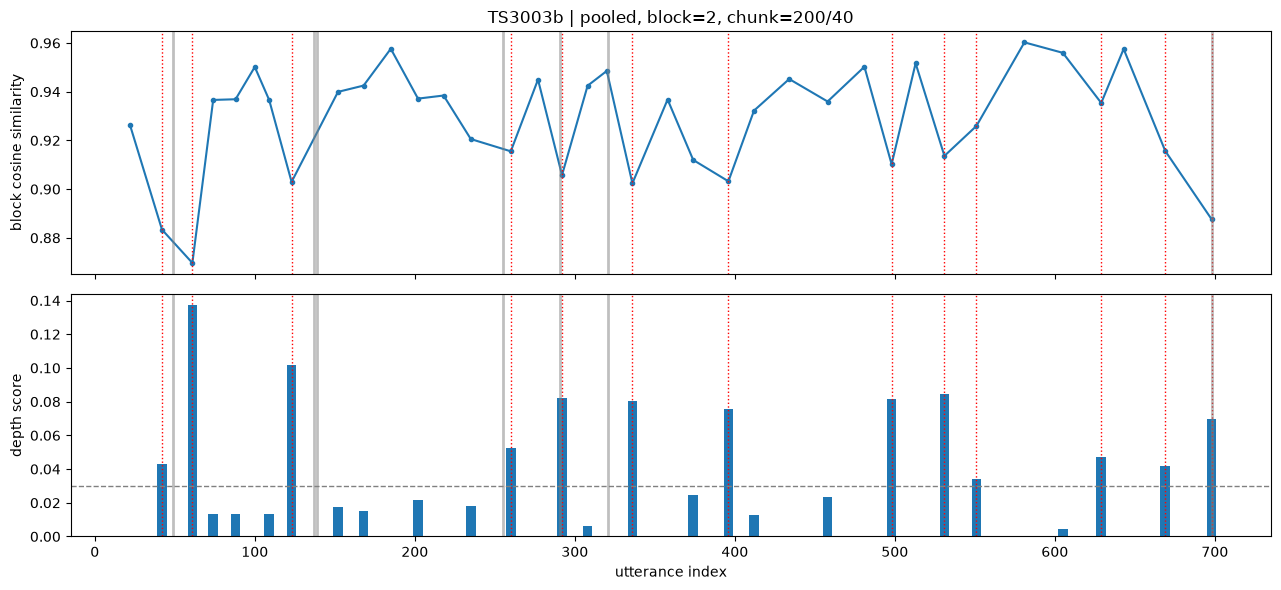

In [11]:
# --------------------------------------------------------------------------------------------------
# +) 유사도 / depth 곡선 시각화 (빨간 점선: 후보, 회색 실선: 정답 최상위 주제 경계, GOLD_PATH 있을 때만)
# --------------------------------------------------------------------------------------------------
import matplotlib.pyplot as plt

x = gaps_df["boundary_position"]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax1.plot(x, gap_sims, marker="o", ms=3)
ax1.set_ylabel("block cosine similarity")
ax2.bar(x, gap_depths, width=6)
ax2.axhline(depth_threshold, ls="--", c="gray", lw=1)
ax2.set_ylabel("depth score")
ax2.set_xlabel("utterance index")
for g in candidate_gaps:
    for ax in (ax1, ax2):
        ax.axvline(gaps_df.loc[g, "boundary_position"], c="red", ls=":", lw=1)
if GOLD_PATH is not None and Path(GOLD_PATH).is_file():
    _gold_tids = [u["tid"].split(".")[0] for u in json.loads(Path(GOLD_PATH).read_text(encoding="utf-8"))["utterances"]]
    for i in range(1, len(_gold_tids)):
        if _gold_tids[i] != _gold_tids[i - 1]:
            for ax in (ax1, ax2):
                ax.axvline(i, c="gray", alpha=0.5, lw=2)
ax1.set_title(f"{meeting_id} | {EMBEDDING_MODE}, block={BLOCK_SIZE}, chunk={CHUNK_SIZE}/{CHUNK_OVERLAP}")
plt.tight_layout()
plt.show()

In [12]:
# --------------------------------------------------------------------------------------------------
# 2-3. LLM 경계 검증 입력 구성
# 경계 후보(boundary_position)를 중앙에 두고 앞/뒤 CONTEXT_TOKENS 토큰만큼의 발화를 각각 하나의 문맥으로 묶음
# left_context: [.., boundary_position - 1] / right_context: [boundary_position, ..]
# 맞장구도 '종결 신호'(좋아요, 그럼 등)일 수 있으므로 문맥에서는 제외하지 않음
# --------------------------------------------------------------------------------------------------
def collect_context(position, direction, max_tokens):
    indices, total = [], 0
    rng = range(position - 1, -1, -1) if direction == "left" else range(position, len(utt_texts))
    for i in rng:
        if indices and total + utt_tokens[i] > max_tokens:
            break
        indices.append(i)
        total += utt_tokens[i]
    indices = sorted(indices)
    return [{"utterance_index": i, "text": utt_texts[i]} for i in indices]


candidates = []
for rank, g in enumerate(sorted(candidate_gaps, key=lambda g: -gap_depths[g])):
    pos = boundary_position(chunks_, g)
    candidates.append({
        "candidate_id": None,
        "boundary_position": pos,                 # 이 발화부터 새 주제라고 보는 후보 위치
        "gap_index": g,                           # chunk g | chunk g+1
        "left_chunk_index": g,
        "right_chunk_index": g + 1,
        "similarity": round(float(gap_sims[g]), 4),
        "depth_score": round(float(gap_depths[g]), 4),
        "depth_rank": rank + 1,
        "left_context": collect_context(pos, "left", CONTEXT_TOKENS),
        "right_context": collect_context(pos, "right", CONTEXT_TOKENS),
    })
candidates.sort(key=lambda c: c["boundary_position"])
for i, c in enumerate(candidates):
    c["candidate_id"] = i

boundary_result = {
    "meeting_id": meeting_id,
    "metadata": header,
    "detection": {
        "embedding_model": EMBEDDING_MODEL,
        "embedding_mode": EMBEDDING_MODE,
        "filler_max_tokens": FILLER_MAX_TOKENS,
        "block_size": BLOCK_SIZE,
        "score": "depth score of block cosine similarity (TextTiling)",
        "depth_std_k": DEPTH_STD_K,
        "depth_threshold": round(float(depth_threshold), 4),
        "min_gap_distance": MIN_GAP_DISTANCE,
        "context_tokens": CONTEXT_TOKENS,
        "chunking": chunk_result["chunking"],
        "num_gaps": len(gap_sims),
        "num_candidates": len(candidates),
    },
    "candidates": candidates,
}


def format_candidate(c, n_preview=3):
    left = c["left_context"][-n_preview:]
    right = c["right_context"][:n_preview]
    lines = [f"=== [{left[-1]['utterance_index']}] | [{right[0]['utterance_index']}] — 위치 {c['boundary_position']} "
             f"(depth={c['depth_score']}, rank={c['depth_rank']}) ===", "왼쪽 문맥:"]
    lines += [f"[{u['utterance_index']}] {u['text']}" for u in left]
    lines += ["오른쪽 문맥:"] + [f"[{u['utterance_index']}] {u['text']}" for u in right]
    return "\n".join(lines)


print(f"경계 후보 {len(candidates)}개 (미리보기: 경계 앞/뒤 3발화, 실제 JSON에는 앞/뒤 {CONTEXT_TOKENS}토큰)\n")
for c in candidates:
    print(format_candidate(c), end="\n\n")

경계 후보 13개 (미리보기: 경계 앞/뒤 3발화, 실제 JSON에는 앞/뒤 200토큰)

=== [41] | [42] — 위치 42 (depth=0.043, rank=11) ===
왼쪽 문맥:
[39] 음, 첫 발표부터 시작하죠.
[40] 네.
[41] 음, 누가 먼저 할래요?
오른쪽 문맥:
[42] 제가 먼저 할게요.
[43] 좋아요.
[44] 그럼

=== [60] | [61] — 위치 61 (depth=0.1371, rank=1) ===
왼쪽 문맥:
[58] 어, 그리고 시장 조사도 좀 했어요. 어, 시장이 어떻게 구성돼 있는지, 어떤 연령대가 있는지요.
[59] 음
[60] 이게 제가 보기에 꽤 놀라운 결과 세 가지예요.
오른쪽 문맥:
[61] 음, 리모컨은 못생겼다고 여겨져요.
[62] 그
[63] 어, 설문 응답자의 75퍼센트가 음, 자기 리모컨이 못생겼다고 답했어요.

=== [122] | [123] — 위치 123 (depth=0.1018, rank=2) ===
왼쪽 문맥:
[120] 그리고 거기에 더해 음, 리모컨을 꽂으면 배터리를 충전할 수도 있고요.
[121] 그리고 음, 놀랍게도 아주 많은 사람들이 음, 리모컨에 LCD 화면이 있으면 좋겠다고 했어요.
[122] 이건 음, 주로 16세에서 25세 사람들이었어요.
오른쪽 문맥:
[123] 그래도 45세까지는 여전히 가능성이 있어요.
[124] 이것도 생산 비용을 크게 늘리겠지만
[125] 그냥 고려해 볼 수 있는 작은 요소들이라고 생각해요.

=== [259] | [260] — 위치 260 (depth=0.0524, rank=9) ===
왼쪽 문맥:
[257] 음, 먼저 작동 방식부터요.
[258] 당연히 정말 간단해요.
[259] 리모컨이 어떻게 작동하는지는 다들 알잖아요.
오른쪽 문맥:
[260] 사용자가 버튼을 누르면,
[261] 리모컨이 어떤 버튼인지 판단해서
[262] 적외선으로 TV에 신호를 보내요.

=== [291] | [292] — 위치 292 (depth=0.082, ra

In [ ]:
# --------------------------------------------------------------------------------------------------
# 2-4. 저장
# 01과 동일하게 기본은 저장하지 않음. 저장하려면 주석 풀고 실행
# "outputs/boundaries" 디렉토리 내 <회의ID>_boundary_candidates.json 파일로 저장됨
# --------------------------------------------------------------------------------------------------
boundary_result

# BOUNDARY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# boundary_path = BOUNDARY_OUTPUT_DIR / f"{meeting_id}_boundary_candidates.json"
# boundary_path.write_text(json.dumps(boundary_result, ensure_ascii=False, indent=2), encoding="utf-8")
# print("저장 완료:", boundary_path)

저장 완료: c:\Users\user\Desktop\한화내일아카데미\remeet\playground\chaewon\outputs\boundaries\TS3003b_boundary_candidates.json


In [14]:
# --------------------------------------------------------------------------------------------------
# 참고) 정답 주제 기반 후보 탐지 평가 (GOLD_PATH가 있을 때만)
# - top    : 최상위 주제(t01, t02 ...) 경계
# - agenda : top + 자유 토론(t07) 안의 하위 주제 경계 → LLM 기준인 '안건 단위'에 가장 가까움
# - random : 같은 개수의 후보를 청크 경계에서 무작위로 뽑았을 때의 평균 (비교 기준선)
# --------------------------------------------------------------------------------------------------
import random


def gold_boundaries(gold_path, discussion_topic="t07"):
    tids = [u["tid"] for u in json.loads(Path(gold_path).read_text(encoding="utf-8"))["utterances"]]
    top = [t.split(".")[0] for t in tids]
    sub = [".".join(t.split(".")[:2]) for t in tids]
    top_b = [i for i in range(1, len(tids)) if top[i] != top[i - 1]]
    agenda_b = sorted(set(top_b) | {i for i in range(1, len(tids))
                                    if sub[i] != sub[i - 1] and top[i] == top[i - 1] == discussion_topic})
    return top_b, agenda_b


def recall_precision(pred, gold, tol):
    if not pred:
        return 0.0, 0.0
    recall = sum(any(abs(p - b) <= tol for p in pred) for b in gold) / len(gold)
    precision = sum(any(abs(p - b) <= tol for b in gold) for p in pred) / len(pred)
    return recall, precision


def random_baseline(n, gold, tol, trials=2000, seed=0):
    rnd = random.Random(seed)
    pool = gaps_df["boundary_position"].tolist()
    scores = [recall_precision(rnd.sample(pool, n), gold, tol) for _ in range(trials)]
    return tuple(np.mean(scores, axis=0))


if GOLD_PATH is not None and Path(GOLD_PATH).is_file():
    gold_top, gold_agenda = gold_boundaries(GOLD_PATH)
    pred = [c["boundary_position"] for c in candidates]
    rows = []
    for name, gold in (("top", gold_top), ("agenda", gold_agenda)):
        r, p = recall_precision(pred, gold, EVAL_TOLERANCE)
        rr, rp = random_baseline(len(pred), gold, EVAL_TOLERANCE)
        rows.append({"gold": name, "num_gold": len(gold), "num_pred": len(pred), "recall": round(r, 2),
                     "precision": round(p, 2), "random_recall": round(rr, 2), "random_precision": round(rp, 2)})
    display(pd.DataFrame(rows))
    print("정답 최상위 경계:", gold_top)
    print("놓친 최상위 경계:", [b for b in gold_top if all(abs(p - b) > EVAL_TOLERANCE for p in pred)])
else:
    print("GOLD_PATH 없음 → 평가 생략")

,gold,num_gold,num_pred,recall,precision,random_recall,random_precision
0,top,7,13,0.57,0.31,0.25,0.13
1,agenda,26,13,0.54,0.69,0.26,0.35


정답 최상위 경계: [49, 137, 139, 255, 291, 321, 698]
놓친 최상위 경계: [137, 139, 321]


# 03. LLM 경계 검증